In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

In [54]:
df = pd.read_csv('/content/Apartments Prices Dataset.csv')

In [55]:
df.head()

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
0,"2,163,000 EGP",120 m²,2 rooms,3 bathroom,3,2025,Developer,Main Street,"18,025 EGP/M²",Installments,Semi Finished
1,"3,250,000 EGP",162 m²,3 rooms,2 bathroom,6,2024,Developer,Main Street,"20,062 EGP/M²",Cash or Installments,Semi Finished
2,"2,650,000 EGP",122 m²,3 rooms,1 bathroom,4,2024,Developer,Main Street,"21,721 EGP/M²",Cash or Installments,Semi Finished
3,"12,720,000 EGP",212 m²,4 rooms,3 bathroom,13,2027,Broker,Club,"60,000 EGP/M²",Cash or Installments,Extra Super Lux
4,"5,898,000 EGP",135 m²,2 rooms,1 bathroom,6,2025,Developer,Lake,"43,689 EGP/M²",Cash or Installments,Super Lux


In [56]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5578 entries, 0 to 5577
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   price           5578 non-null   object
 1   area_sqm        5578 non-null   object
 2   rooms           5578 non-null   object
 3   bathrooms       5578 non-null   object
 4   floor_level     5578 non-null   object
 5   year_built      5578 non-null   int64 
 6   seller_type     5578 non-null   object
 7   view            5578 non-null   object
 8   price_per_sqm   5578 non-null   object
 9   payment_method  5578 non-null   object
 10  finishing_type  5578 non-null   object
dtypes: int64(1), object(10)
memory usage: 479.5+ KB


In [57]:
df.describe()

,year_built
count,5578.000000
mean,2022.327178
std,8.431095
min,1915.000000
25%,2023.000000
50%,2025.000000
75%,2026.000000
max,2037.000000


In [58]:
df.describe(include=object)

,price,area_sqm,rooms,bathrooms,floor_level,seller_type,view,price_per_sqm,payment_method,finishing_type
count,5578,5578,5578,5578,5578,5578,5578,5578,5578,5578
unique,1321,251,11,11,22,7,13,2127,3,5
top,"6,500,000 EGP",140 m²,3 rooms,1 bathroom,1,Broker,Main Street,"50,000 EGP/M²",Cash,Super Lux
freq,94,174,3099,1969,1831,4872,1725,103,2571,2264


In [59]:
df.duplicated().sum()

np.int64(1489)

In [60]:
df.drop_duplicates(inplace=True)

In [61]:
df['price'] = (df['price']
               .str.replace('EGP', '', regex=False)
               .str.replace(',', '', regex=False)
               .str.strip()
               .astype(int))

In [62]:
df['area_sqm']= (df['area_sqm']
               .str.replace('m²', '', regex=False)
               .str.strip()
               .astype(int))

In [63]:
df['rooms']=(df['rooms'].str.replace('rooms', '', regex=False).str.strip().astype(int))

In [64]:
df['bathrooms']= (df['bathrooms']
               .str.replace('bathroom', '', regex=False)
               .str.strip()
               .astype(int))

In [65]:
df[df['price_per_sqm']=='Developer']

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
70,27000000,164,2,3,4,2027,Cash or Installments,Nile View,Developer,Cash or Installments,Extra Super Lux
416,4900000,215,3,3,8,2012,Cash,Main Street,Developer,Cash,Extra Super Lux
576,2700000,126,3,1,4,1990,Cash or Installments,Main Street,Developer,Cash or Installments,Super Lux
777,4300000,200,3,2,4,1989,Cash or Installments,Side Street,Developer,Cash or Installments,Extra Super Lux
1269,2700000,120,2,1,3,1988,Cash or Installments,Main Street,Developer,Cash or Installments,Extra Super Lux
2908,25000000,164,2,3,4,2027,Installments,Nile View,Developer,Installments,Extra Super Lux


In [66]:
df = df[~df['price_per_sqm'].isin(['Developer', 'Broker','Private Owner'])].copy()

In [67]:
df['price_per_sqm'] = (
    df['price_per_sqm']
    .str.replace('EGP/M²', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.strip().astype(int)
)


In [68]:
df['floor_level']=df['floor_level'].replace({
    'Ground': '0'
}).str.strip().astype(int)

In [69]:
df.describe()

,price,area_sqm,rooms,bathrooms,floor_level,year_built,price_per_sqm
count,4.059000e+03,4059.000000,4059.000000,4059.000000,4059.000000,4059.000000,4059.000000
mean,6.259027e+06,151.713969,2.717418,2.102488,2.980537,2021.978320,42771.296871
std,4.669669e+06,54.810838,4.140547,0.968626,2.790247,8.808433,28029.856346
min,5.000000e+05,15.000000,1.000000,1.000000,0.000000,1915.000000,4167.000000
25%,3.500000e+06,119.000000,2.000000,1.000000,1.000000,2022.000000,25000.000000
50%,5.194000e+06,150.000000,3.000000,2.000000,2.000000,2025.000000,36905.000000
75%,7.700000e+06,180.000000,3.000000,3.000000,4.000000,2026.000000,53914.000000
max,9.838000e+07,534.000000,230.000000,23.000000,64.000000,2037.000000,655172.000000


In [70]:
df[df['rooms']==230]

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
1841,8500000,230,230,3,6,1990,Broker,Other,36957,Cash,Super Lux


In [71]:
df = df.drop(index=1841).reset_index(drop=True)

In [72]:
df[df['rooms']==123]

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
3905,6650000,123,123,2,2,2025,Broker,Garden,54065,Cash or Installments,Extra Super Lux


In [73]:
df = df.drop(index=3905).reset_index(drop=True)

In [74]:
df[df['rooms']==33]

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
3685,5000000,165,33,2,4,2011,Broker,Main Street,30303,Cash,Extra Super Lux


In [75]:
df = df.drop(index=3685).reset_index(drop=True)

In [76]:
df = df[df['bathrooms'] <= 5].copy()

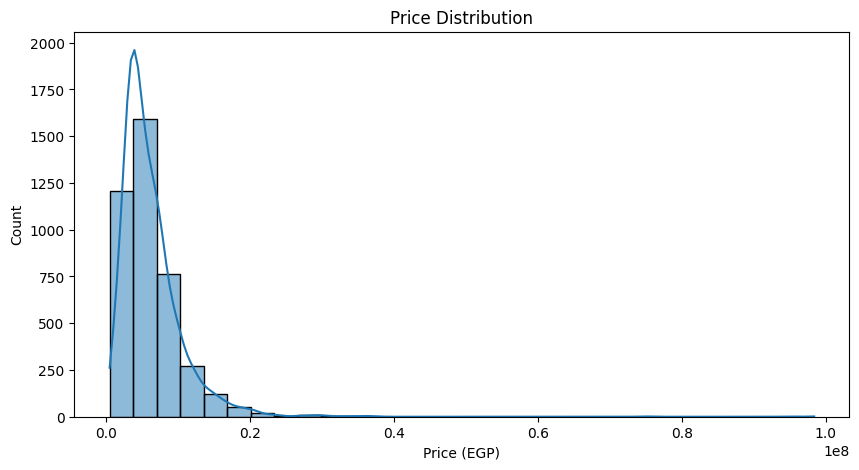

In [77]:
plt.figure(figsize=(10,5))
sns.histplot(df['price'], kde=True, bins=30)
plt.title('Price Distribution')
plt.xlabel('Price (EGP)')
plt.show()

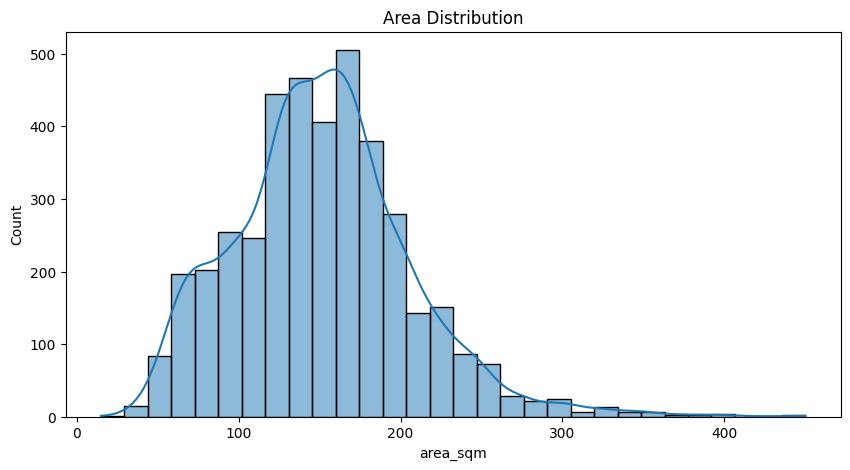

In [78]:
plt.figure(figsize=(10,5))
sns.histplot(df['area_sqm'], kde=True, bins=30)
plt.title('Area Distribution')
plt.show()

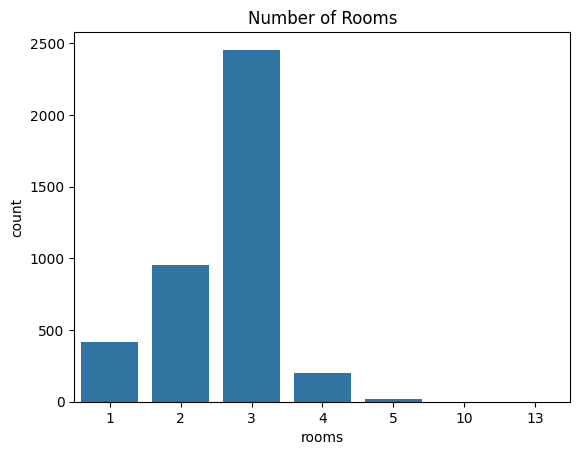

In [79]:
sns.countplot(data=df, x='rooms')
plt.title('Number of Rooms')
plt.show()

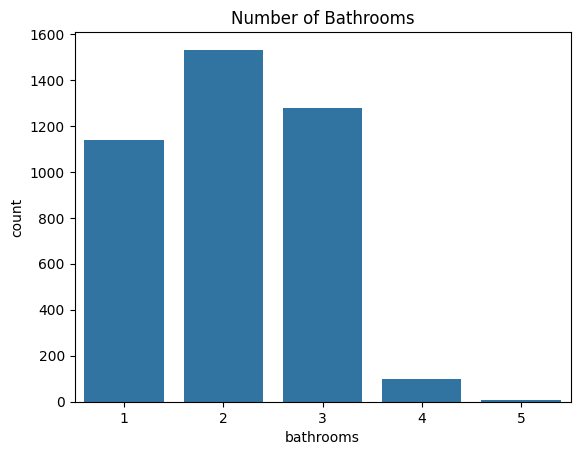

In [80]:
sns.countplot(data=df, x='bathrooms')
plt.title('Number of Bathrooms')
plt.show()

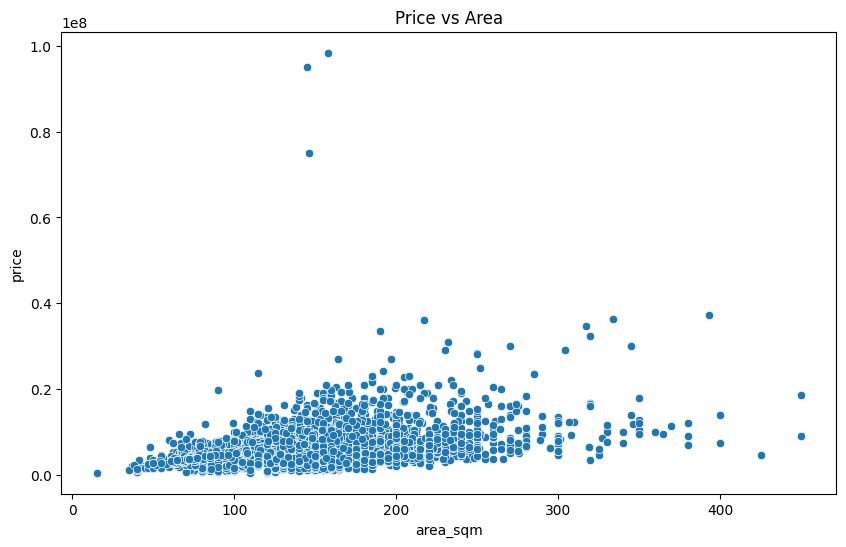

In [81]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='area_sqm', y='price')
plt.title('Price vs Area')
plt.show()

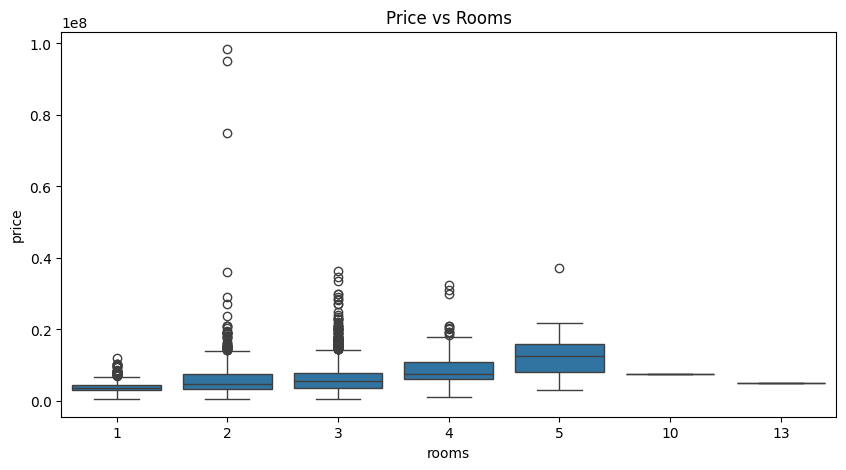

In [82]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df, x='rooms', y='price')
plt.title('Price vs Rooms')
plt.show()

In [83]:
df[df['price']>20000000]

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
21,34650000,317,3,2,3,2028,Broker,Sea View,109306,Cash or Installments,Super Lux
22,20538000,163,2,1,2,2028,Broker,Sea View,126000,Cash or Installments,Super Lux
257,21906000,185,5,4,3,2025,Broker,Lake,118411,Cash or Installments,Without Finish
281,28470360,250,3,2,1,2025,Broker,Other,113881,Cash,Super Lux
290,28216000,250,3,2,1,2019,Broker,Main Street,112864,Cash,Super Lux
391,32391245,320,4,3,7,2025,Broker,Other,101223,Cash,Super Lux
425,29157000,230,2,2,1,2019,Broker,Main Street,126770,Cash,Super Lux
472,75000000,146,2,2,1,2025,Developer,Sea View,513699,Cash,Extra Super Lux
709,98380000,158,2,3,5,2023,Broker,Garden,622658,Cash,Extra Super Lux
782,20500000,260,4,4,3,2025,Broker,Main Street,78846,Installments,Extra Super Lux


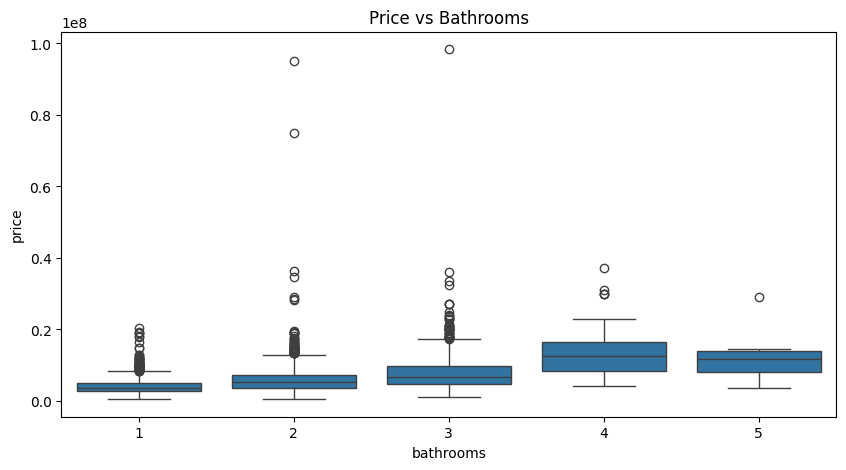

In [84]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df, x='bathrooms', y='price')
plt.title('Price vs Bathrooms')
plt.show()

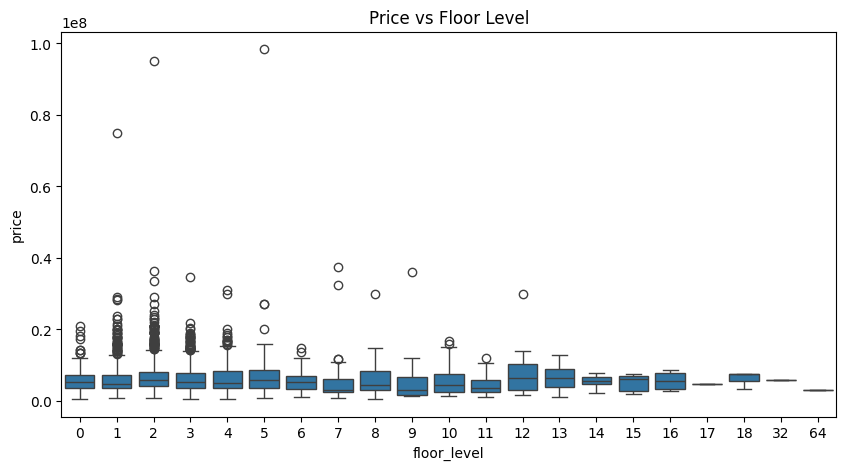

In [85]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df, x='floor_level', y='price')
plt.title('Price vs Floor Level')
plt.show()

In [86]:
df[df['floor_level']>32]

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
246,3082000,64,1,1,64,2026,Broker,Side Street,48156,Installments,Super Lux


In [87]:
df = df.drop(index=246).reset_index(drop=True)

In [88]:
df[df['year_built'] > 2026]

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
3,12720000,212,4,3,13,2027,Broker,Club,60000,Cash or Installments,Extra Super Lux
6,6329000,145,3,3,2,2027,Broker,Other,43648,Installments,Semi Finished
12,5166000,228,3,3,2,2027,Broker,Main Street,22658,Installments,Semi Finished
16,3660000,130,3,2,0,2027,Broker,Main Street,28154,Installments,Semi Finished
17,19026000,151,2,1,3,2028,Broker,Sea View,126000,Cash or Installments,Super Lux
...,...,...,...,...,...,...,...,...,...,...,...
3990,23500000,285,3,3,2,2027,Broker,Garden,82456,Cash or Installments,Semi Finished
4023,5000000,181,3,3,2,2028,Broker,Pool,27624,Cash or Installments,Without Finish
4035,4000000,157,3,3,2,2027,Broker,Pool,25478,Cash or Installments,Without Finish
4043,4420000,85,2,1,2,2027,Broker,Pool,52000,Installments,Super Lux


In [89]:
num_cols = df.select_dtypes(include=['int64']).columns.tolist()

print(num_cols)
cat_cols = df.select_dtypes(include=['object', 'category']).columns

print(cat_cols)

['price', 'area_sqm', 'rooms', 'bathrooms', 'floor_level', 'year_built', 'price_per_sqm']
Index(['seller_type', 'view', 'payment_method', 'finishing_type'], dtype='object')


In [90]:
num_cols = [col for col in num_cols if col not in ['price', 'price_per_sqm']]
df = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)

In [91]:
X=df.drop('price',axis =1)
y= df[['price']]

In [92]:
# Split into Input and Output Elements
X_train, X_test, y_train, y_test = train_test_split(X,y,
                                   test_size= 0.20, random_state=100)

In [93]:
print("X_train = ",X_train.shape ," y_train = ", y_train.shape)
print("X_test  = ",X_test.shape ," y_test  = ", y_test.shape)

X_train =  (3240, 27)  y_train =  (3240, 1)
X_test  =  (810, 27)  y_test  =  (810, 1)


In [94]:

scaler = StandardScaler()

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [95]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [96]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]

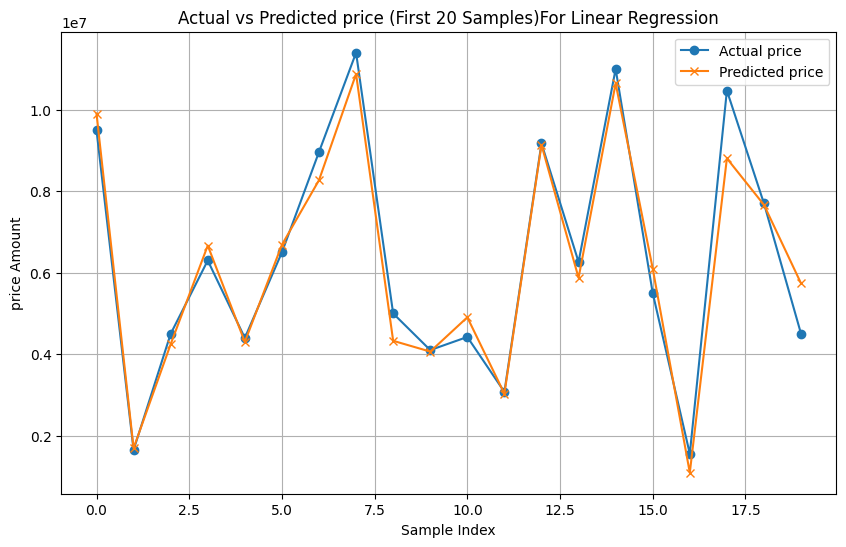

  7%|▋         | 1/15 [00:00<00:11,  1.17it/s]

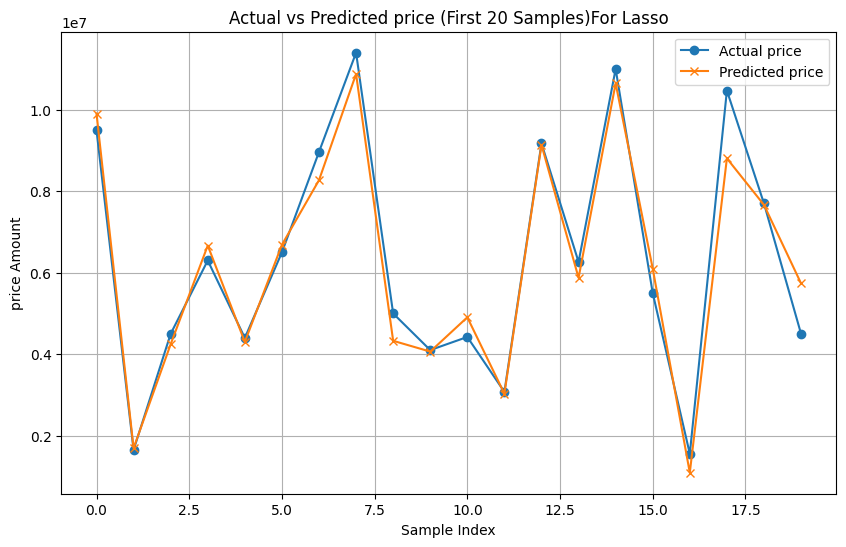

 13%|█▎        | 2/15 [00:02<00:14,  1.13s/it]

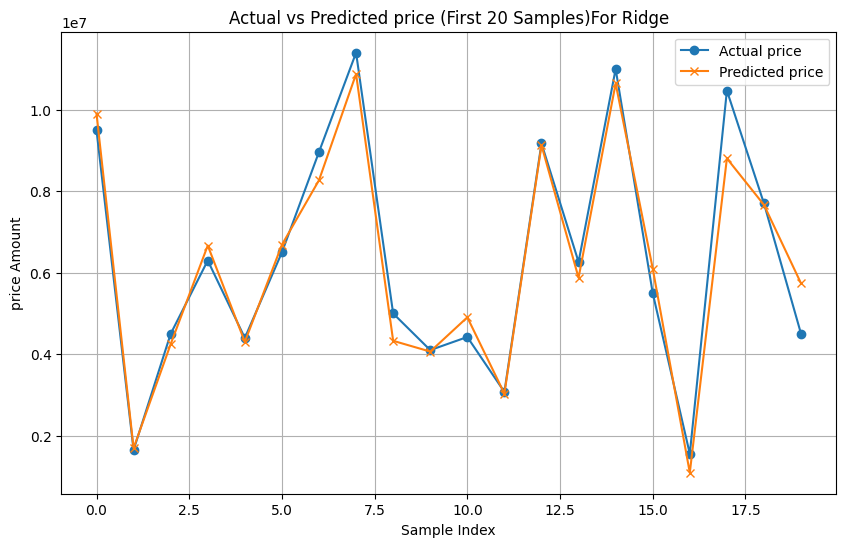

 20%|██        | 3/15 [00:03<00:13,  1.11s/it]

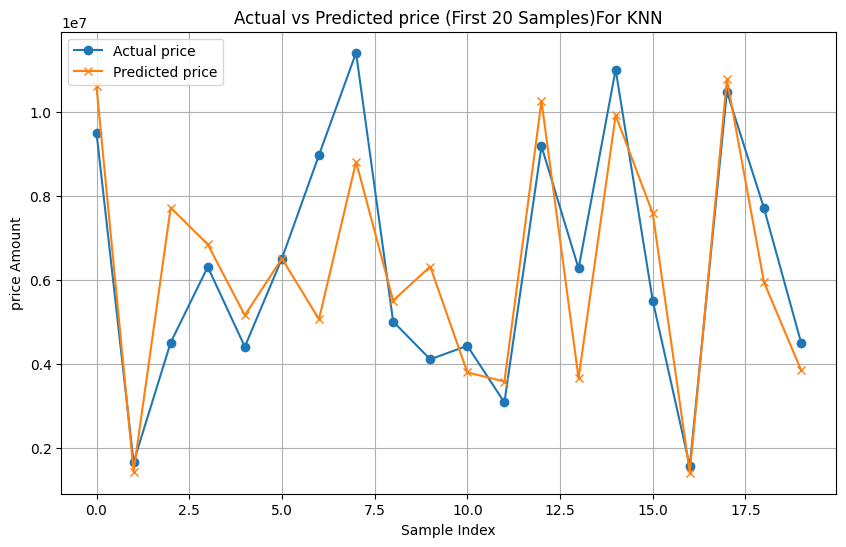

 27%|██▋       | 4/15 [00:05<00:15,  1.41s/it]/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


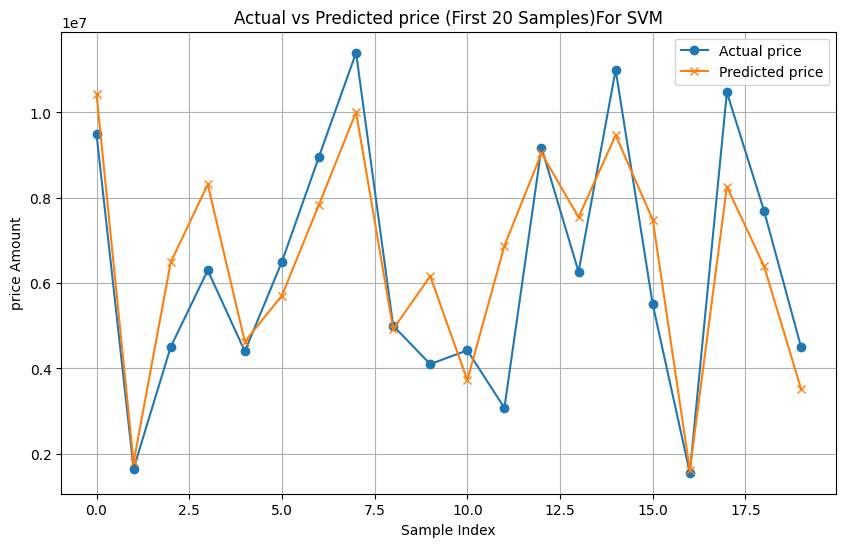

 33%|███▎      | 5/15 [07:20<26:19, 157.93s/it]

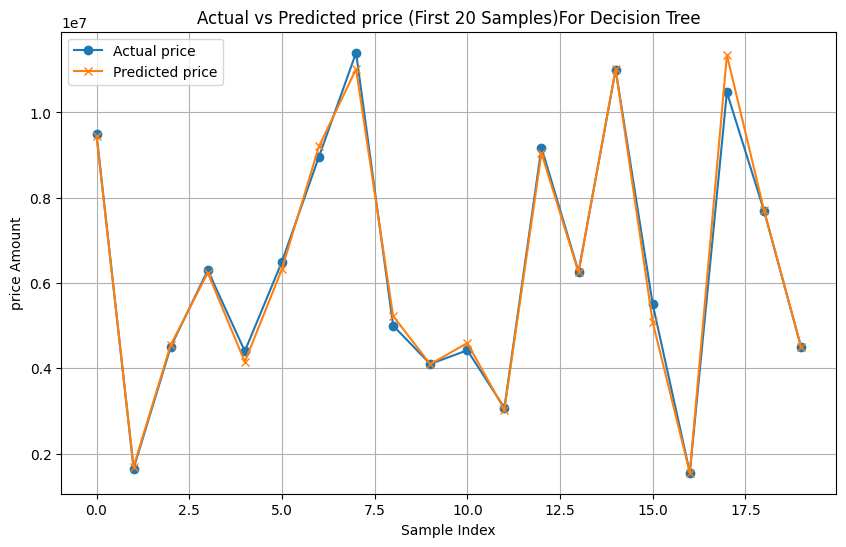

 40%|████      | 6/15 [07:20<15:38, 104.32s/it]/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


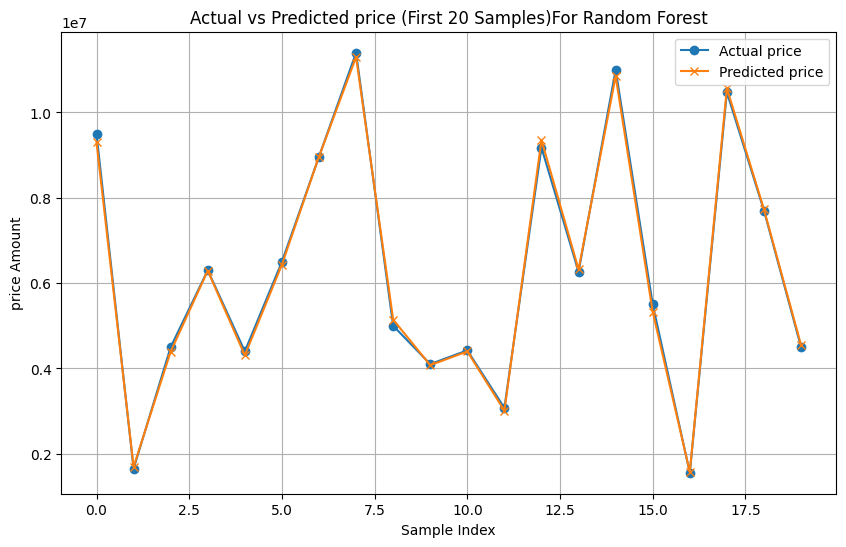

 47%|████▋     | 7/15 [07:21<09:24, 70.52s/it] /usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


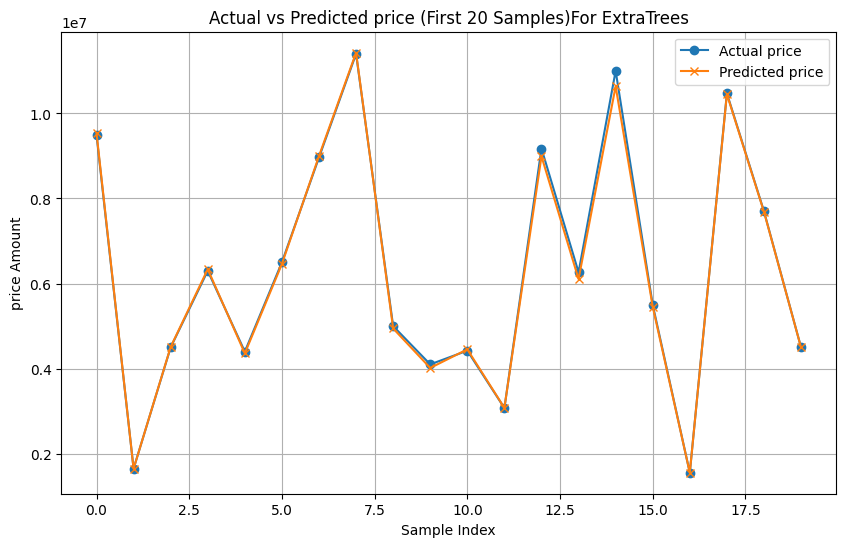

 53%|█████▎    | 8/15 [07:23<05:40, 48.71s/it]/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_bagging.py:568: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  return column_or_1d(y, warn=True)


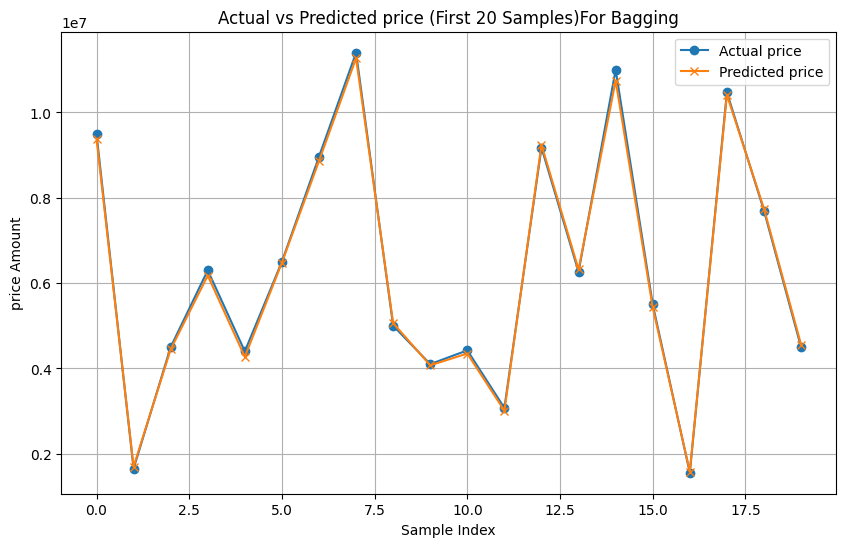

 60%|██████    | 9/15 [07:24<03:22, 33.79s/it]/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


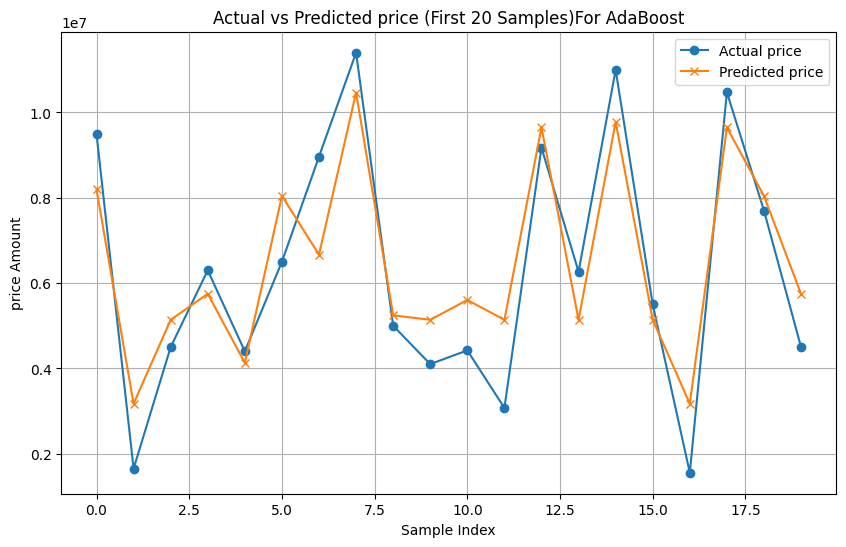

 67%|██████▋   | 10/15 [07:25<01:57, 23.47s/it]/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_gb.py:672: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)  # TODO: Is this still required?


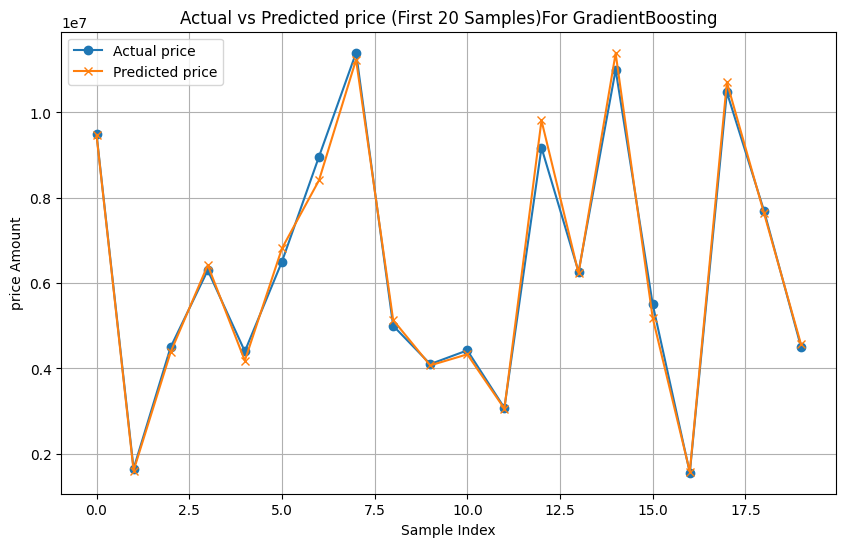

 73%|███████▎  | 11/15 [07:25<01:06, 16.53s/it]/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


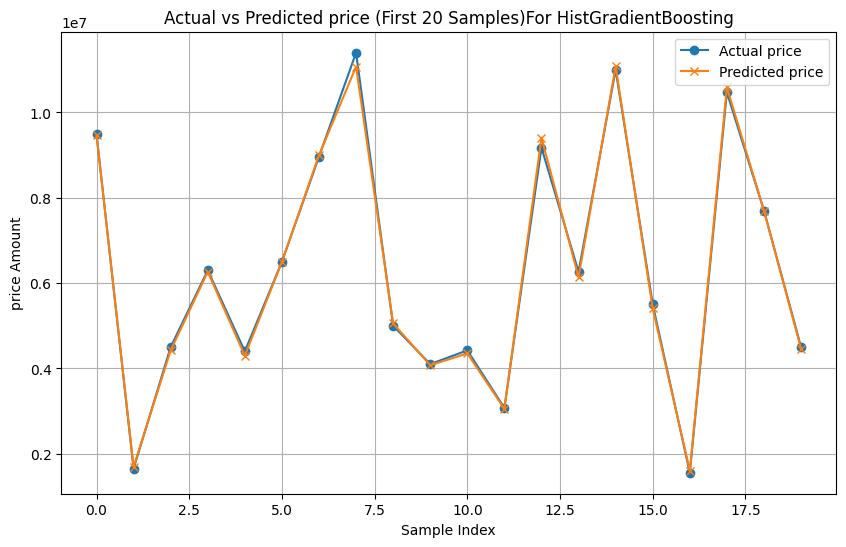

 80%|████████  | 12/15 [07:26<00:35, 11.71s/it]

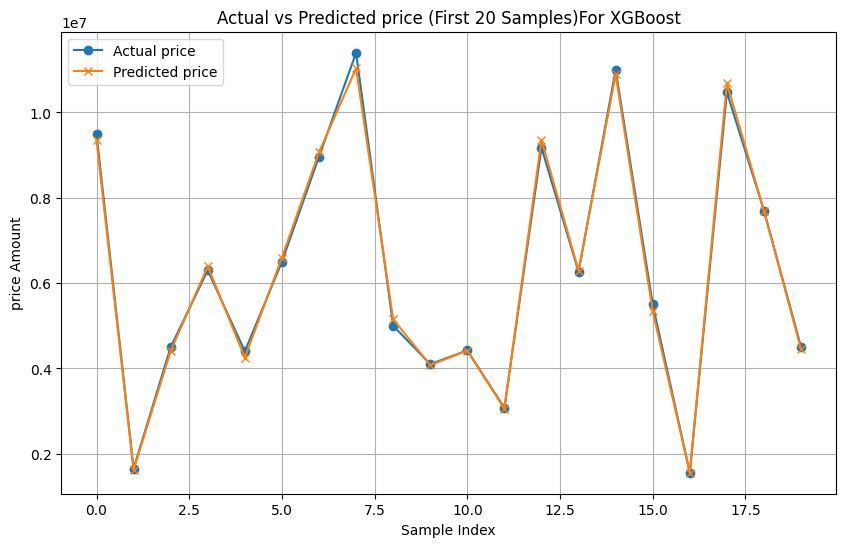

 87%|████████▋ | 13/15 [07:27<00:16,  8.38s/it]

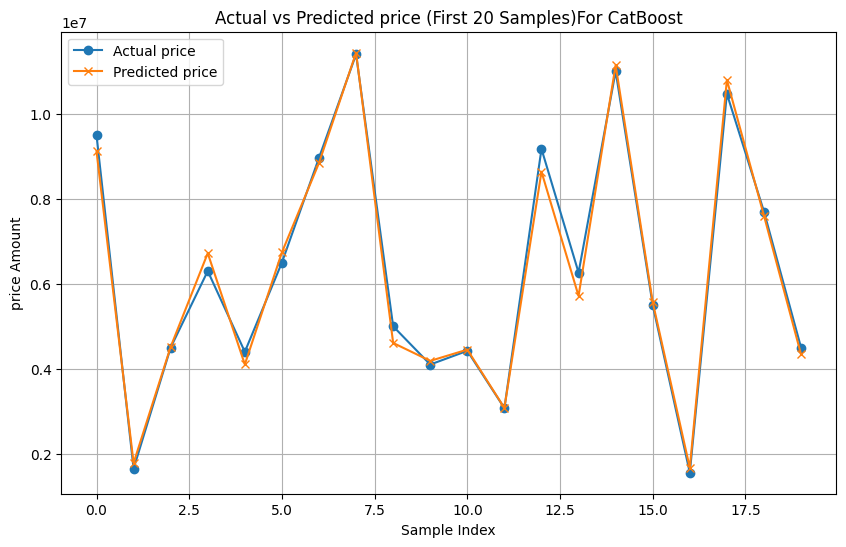

 93%|█████████▎| 14/15 [07:27<00:06,  6.04s/it]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.005412 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 568
[LightGBM] [Info] Number of data points in the train set: 3240, number of used features: 23
[LightGBM] [Info] Start training from score 6272429.843827


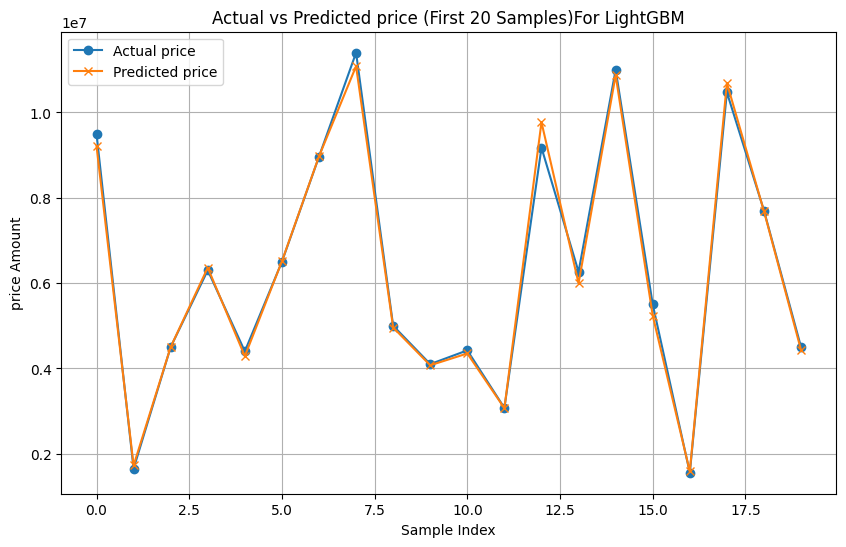

100%|██████████| 15/15 [07:28<00:00, 29.90s/it]


In [47]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)

    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual price', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted price', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('price Amount')
    plt.title('Actual vs Predicted price (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [48]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model1, X_test, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model2, X_test, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model3, X_test, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }


/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_voting.py:698: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_voting.py:698: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_voting.py:698: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [49]:
# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_stacking.py:1060: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [ ]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)
errors_df

In [ ]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

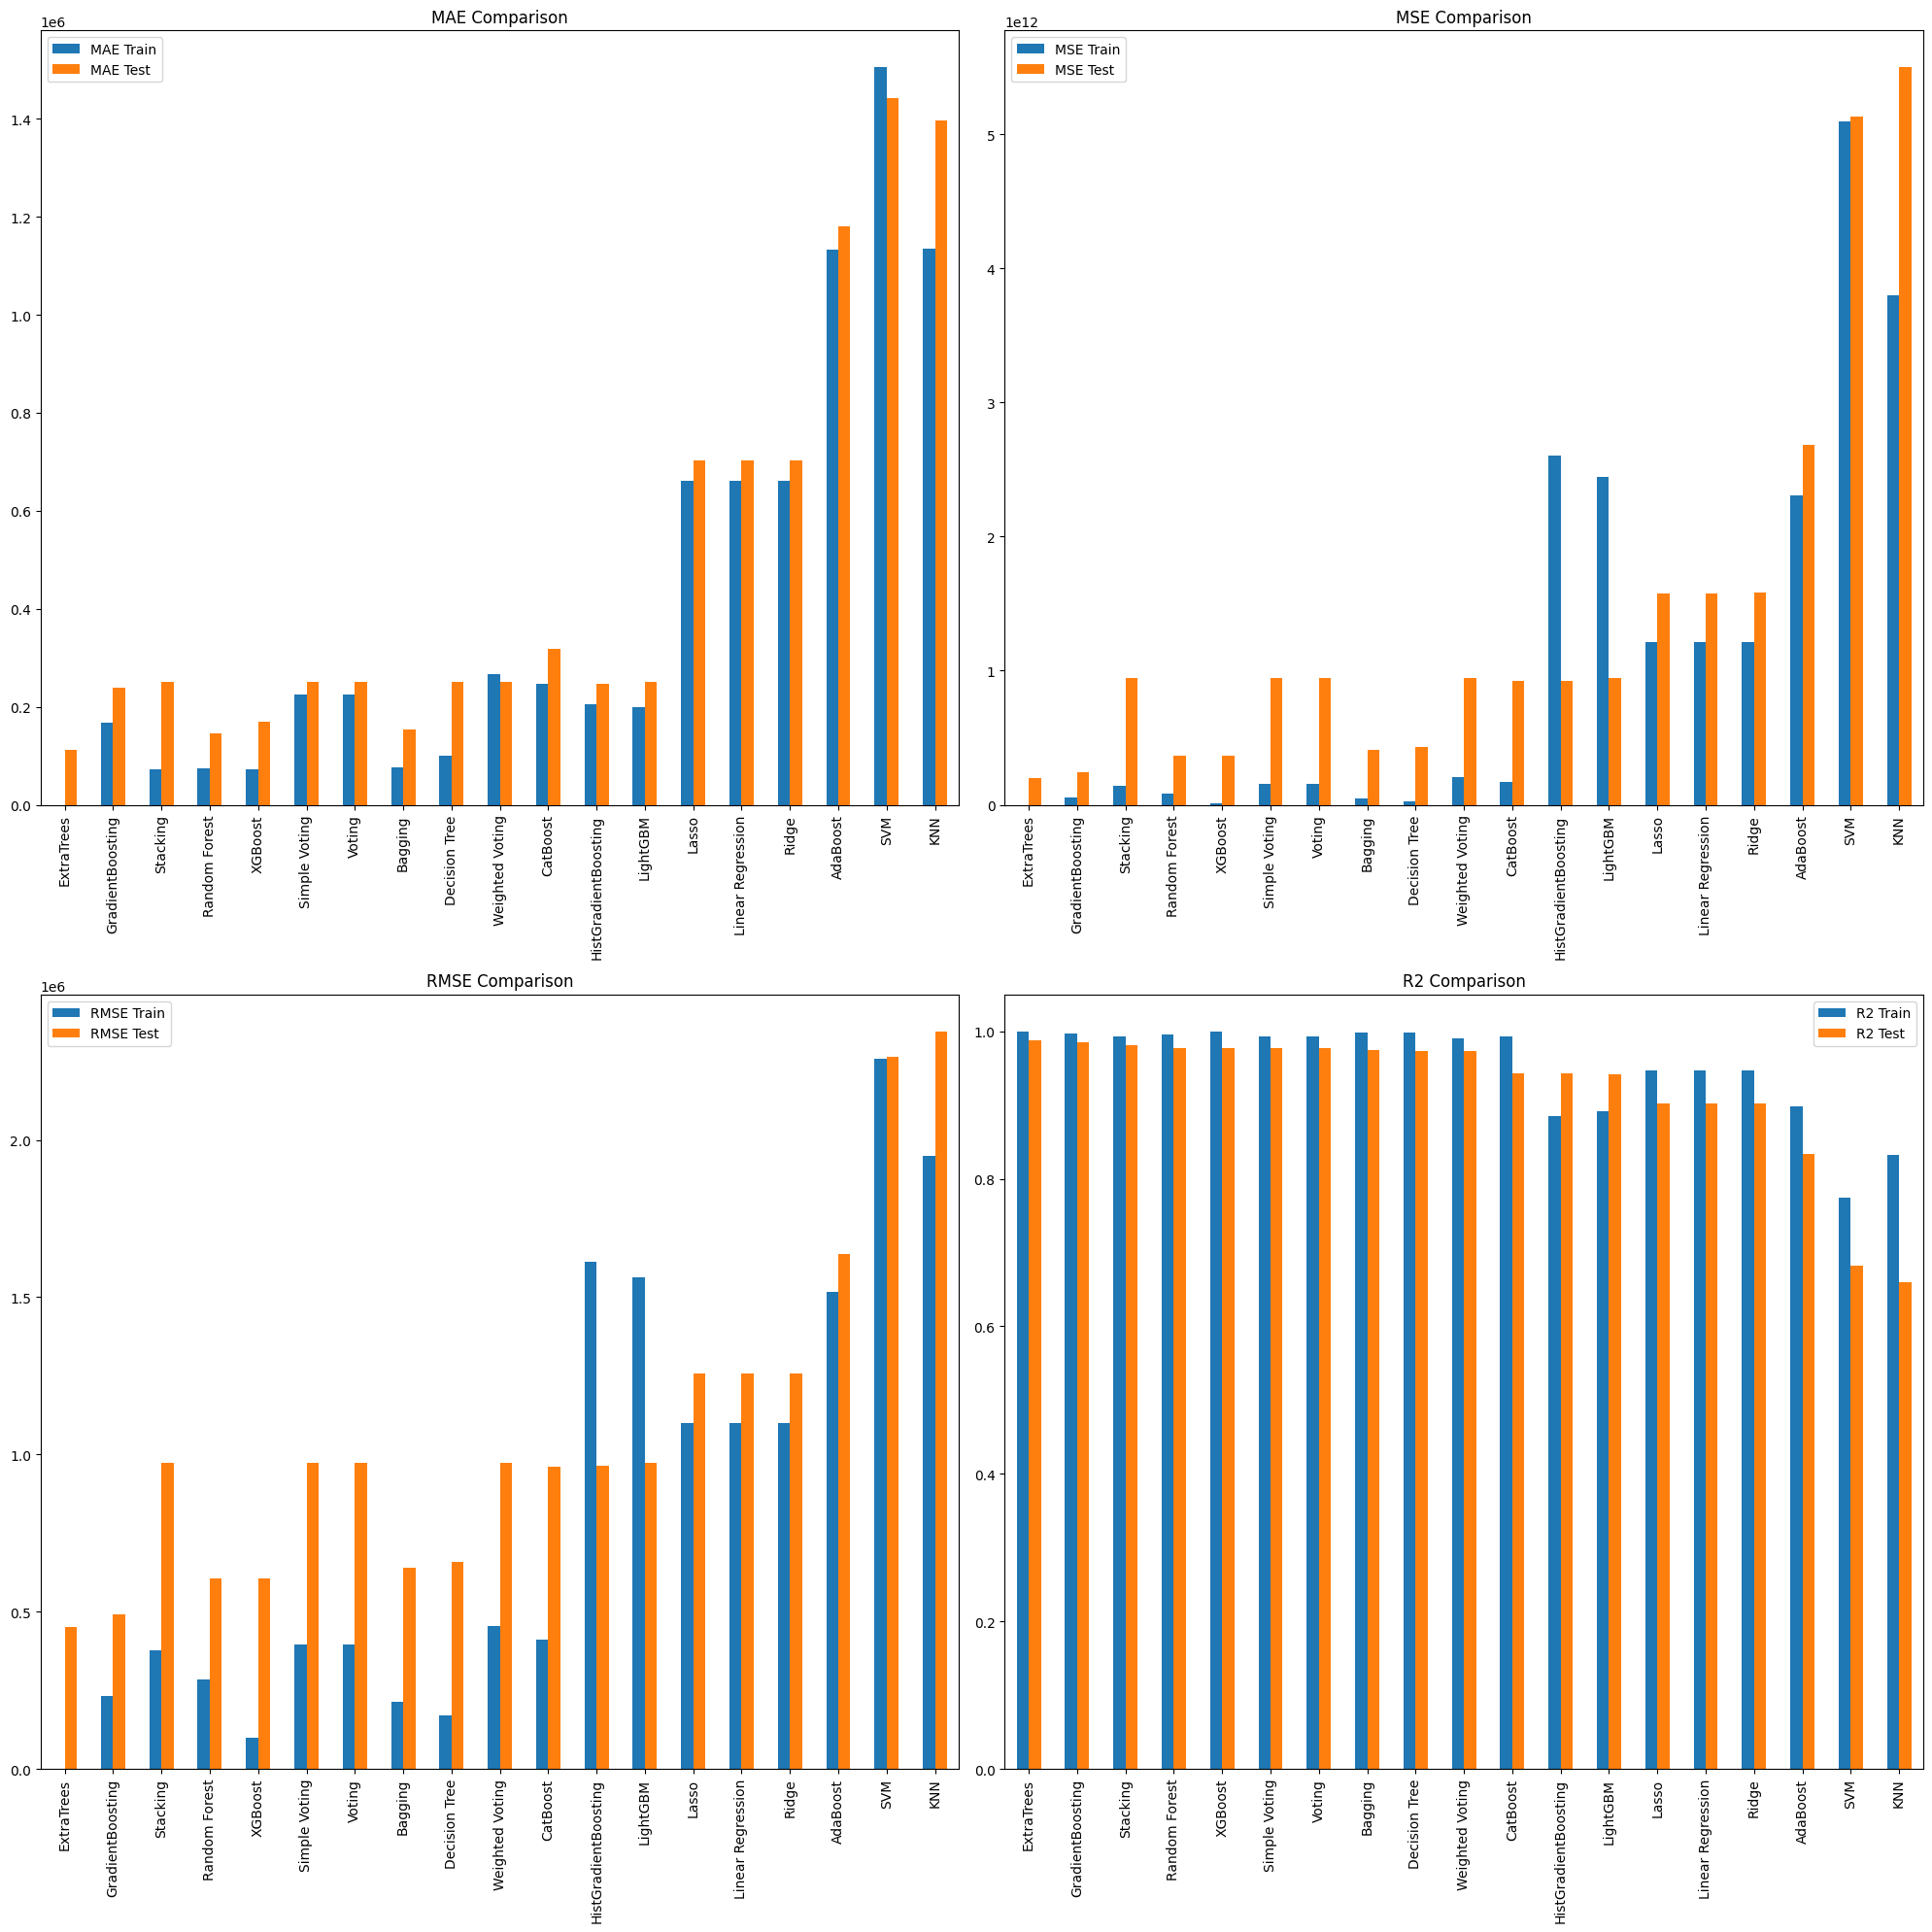

In [52]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()